<a href="https://colab.research.google.com/github/deepak-kumar-da/smart-comment-classifier/blob/main/notebooks/01_dataset_quality_and_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [ ]:
import os
import json
import re
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE = "/content/drive/MyDrive/Smart_Comment_Classifier"

RAW = f"{BASE}/datasets/raw"
PROCESSED = f"{BASE}/datasets/processed"
REPORTS = f"{BASE}/datasets/reports"

os.makedirs(PROCESSED, exist_ok=True)
os.makedirs(REPORTS, exist_ok=True)

In [ ]:
file_paths = {
    "jigsaw":f"{RAW}/jigsaw_toxic_train.csv",
    "uci_youtube":f"{RAW}/uci_youtube_spam.csv",
    "youtube_45k":f"{RAW}/youtube_45k_raw.csv",
    "spamid_pair":f"{RAW}/spamid_pair_analyzed.csv"
}

datasets = {}

for name,path in file_paths.items():
  if not os.path.exists(path):
    raise FileNotFoundError(f"Missing Dataset:{path}")


  if name == "spamid_pair":
    datasets[name] = pd.read_csv(path, sep=';', low_memory=False, on_bad_lines='skip')
  else:
    datasets[name] = pd.read_csv(path, low_memory=False)
  print(f"{name}:{datasets[name].shape[0]} rows "
  f"| {datasets[name].shape[1]} columns")

jigsaw:159571 rows | 8 columns
uci_youtube:1956 rows | 4 columns
youtube_45k:45005 rows | 14 columns
spamid_pair:72999 rows | 1024 columns


In [ ]:
# column and data type inspection

for name,df in datasets.items():
  print("\n" + "="*75)
  print("DATASET:",name.upper())
  print("="*75)

  schema = pd.DataFrame({
      "column":df.columns,
      "dtype":df.dtypes.astype(str).values,
      "missing":df.isnull().sum().values,
      "missing_pct":(
          df.isnull().mean().values*100
      ).round(2),
      "unique_values":df.nunique(dropna=True).values
  })

  display(schema)


DATASET: JIGSAW


,column,dtype,missing,missing_pct,unique_values
0,id,object,0,0.0,159571
1,comment_text,object,0,0.0,159571
2,toxic,int64,0,0.0,2
3,severe_toxic,int64,0,0.0,2
4,obscene,int64,0,0.0,2
5,threat,int64,0,0.0,2
6,insult,int64,0,0.0,2
7,identity_hate,int64,0,0.0,2



DATASET: UCI_YOUTUBE


,column,dtype,missing,missing_pct,unique_values
0,AUTHOR,object,0,0.00,1792
1,DATE,object,245,12.53,1709
2,CONTENT,object,0,0.00,1760
3,CLASS,int64,0,0.00,2



DATASET: YOUTUBE_45K


,column,dtype,missing,missing_pct,unique_values
0,channel_username,object,0,0.00,66
1,channel_id,object,0,0.00,67
2,video_id,object,0,0.00,5918
3,video_title,object,51,0.11,5875
4,comment_text,object,5,0.01,39914
5,comment_id,object,0,0.00,44741
6,author,object,8,0.02,35344
7,published_at,object,0,0.00,44387
8,like_count,int64,0,0.00,348
9,reply_count,int64,0,0.00,215



DATASET: SPAMID_PAIR


,column,dtype,missing,missing_pct,unique_values
0,igid,object,125,0.17,26
1,comment,object,125,0.17,44624
2,posting,object,125,0.17,1914
3,emoji,float64,125,0.17,2
4,spam,float64,125,0.17,2
...,...,...,...,...,...
1019,Unnamed: 1019,float64,72999,100.00,0
1020,Unnamed: 1020,float64,72999,100.00,0
1021,Unnamed: 1021,float64,72999,100.00,0
1022,Unnamed: 1022,float64,72999,100.00,0


In [ ]:
# identify text columns

text_keywords = [
    "text","comment","content","message",
    "review","body","tweet","post"
]

excluded_keywords = [
    "label","class","spam","toxic",
    "sentiment","target","id","score",
    "rating","category","hate","threat"
]

text_candidates = {}

for name,df in datasets.items():
  candidates = []
  for col in df.columns:
    col_lower = str(col).lower()
    if any(k in col_lower for k in excluded_keywords):
      continue
    if not(
        pd.api.types.is_object_dtype(df[col]) or
        pd.api.types.is_string_dtype(df[col])
    ):
      continue

    sample = df[col].dropna().astype(str).head(1000)
    if len(sample) == 0:
      continue

    avg_length = sample.str.len().mean()
    unique_ratio = sample.nunique()/len(sample)

    keyword_match = any(
        keyword in col_lower for keyword in text_keywords
    )

    score = (
        (10 if keyword_match else 0)
        + min(avg_length/20,5)
        + unique_ratio
    )

    candidates.append({
        "column":col,
        "average_text_length":round(avg_length,2),
        "unique_ratio":round(unique_ratio,3),
        "score":round(score,2)
    })

  candidates_df = pd.DataFrame(candidates)

  if not candidates_df.empty:
    candidates_df = candidates_df.sort_values(
        "score",ascending=False)

    text_candidates[name] = candidates_df
    print("\n",name.upper())
    display(candidates_df)


 JIGSAW


,column,average_text_length,unique_ratio,score
0,comment_text,405.5,1.0,16.0



 UCI_YOUTUBE


,column,average_text_length,unique_ratio,score
2,CONTENT,84.10,0.947,15.15
1,DATE,21.10,0.999,2.05
0,AUTHOR,13.16,0.971,1.63



 YOUTUBE_45K


,column,average_text_length,unique_ratio,score
1,comment_text,116.54,0.994,15.99
3,published_at,20.00,1.000,2.00
2,author,15.23,0.971,1.73
0,channel_username,12.00,0.054,0.65
4,language,2.00,0.032,0.13



 SPAMID_PAIR


,column,average_text_length,unique_ratio,score
1,posting,505.46,0.028,15.03
0,comment,27.60,0.714,12.09


In [ ]:
# inspecting label and text candidates

for name,df in datasets.items():
  print("\n" + "="*75)
  print("DATASET:",name.upper())
  print("="*75)

  print("\nPossible Txt Columns:",text_candidates[name]["column"].to_list())

  print("\nPossible label columns:")
  for col in df.columns:
    col_lower = str(col).lower()
    if any(
        k in col_lower for k in ["label","class","spam","toxic","sentiment","hate","threat","obscene","insult"]
    ):
      print(f"\n{col}")
      print(df[col].value_counts(dropna=False).head(20))


DATASET: JIGSAW

Possible Txt Columns: ['comment_text']

Possible label columns:

toxic
toxic
0    144277
1     15294
Name: count, dtype: int64

severe_toxic
severe_toxic
0    157976
1      1595
Name: count, dtype: int64

obscene
obscene
0    151122
1      8449
Name: count, dtype: int64

threat
threat
0    159093
1       478
Name: count, dtype: int64

insult
insult
0    151694
1      7877
Name: count, dtype: int64

identity_hate
identity_hate
0    158166
1      1405
Name: count, dtype: int64

DATASET: UCI_YOUTUBE

Possible Txt Columns: ['CONTENT', 'DATE', 'AUTHOR']

Possible label columns:

CLASS
CLASS
1    1005
0     951
Name: count, dtype: int64

DATASET: YOUTUBE_45K

Possible Txt Columns: ['comment_text', 'published_at', 'author', 'channel_username', 'language']

Possible label columns:

label_sentiment
label_sentiment
neutral     22985
positive    18210
negative     3810
Name: count, dtype: int64

label_toxicity
label_toxicity
non-toxic    43105
toxic         1900
Name: count, dty

In [ ]:
structural_report = []

for name,df in datasets.items():
  all_missing_cols = df.columns[df.isna().all()].tolist()
  report = {
      "dataset":name,
      "rows":len(df),
      "columns":len(df.columns),
      "fully_empty_columns":all_missing_cols,
      "missing_cells":int(df.isna().sum().sum()),
      "columns_with_missing_cells":{
          col:int(count) for col,count in df.isna().sum().items()
          if count > 0
      }
  }

  structural_report.append(report)

  print("\n",name.upper())
  print("Fully empty columns:",all_missing_cols)
  print("Missing cells:",report["missing_cells"])
  print("Missing by column:")
  print(df.isna().sum()[df.isna().sum()>0])




 JIGSAW
Fully empty columns: []
Missing cells: 0
Missing by column:
Series([], dtype: int64)

 UCI_YOUTUBE
Fully empty columns: []
Missing cells: 245
Missing by column:
DATE    245
dtype: int64

 YOUTUBE_45K
Fully empty columns: []
Missing cells: 5035
Missing by column:
video_title       51
comment_text       5
author             8
language        4971
dtype: int64

 SPAMID_PAIR
Fully empty columns: ['Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47', 'Unnamed: 48', 'Unnamed: 49', 'Unnamed: 

In [ ]:
# duplicate comments analysis

text_columns = {
    "jigsaw": "comment_text",
    "uci_youtube": "CONTENT",
    "youtube_45k": "comment_text",
    "spamid_pair": "comment"
}

def normalize_text(text):
  if pd.isna(text):
    return ""

  text = str(text).lower()
  text = re.sub(r"https?://\S+", "URL", text)
  text = re.sub(r"\s+", " ", text)

  return text.strip()

duplicate_report = []
for name, df in datasets.items():
  col = text_columns[name]
  original = df[col].dropna().astype(str)
  normalized = original.apply(normalize_text)

  exact_duplicate_rows = int(original.duplicated().sum())
  normalized_duplicate_rows = int(normalized.duplicated().sum())

  result = {
      "dataset": name,
      "total_rows": len(df),
      "missing_text": int(df[col].isna().sum()),
      "exact_duplicate_text_rows": exact_duplicate_rows,
      "normalized_duplicate_text_rows": normalized_duplicate_rows,
      "unique_normalized_comments": int(normalized.nunique())
  }

  duplicate_report.append(result)

  print("\n", name.upper())
  print(result)


 JIGSAW
{'dataset': 'jigsaw', 'total_rows': 159571, 'missing_text': 0, 'exact_duplicate_text_rows': 0, 'normalized_duplicate_text_rows': 273, 'unique_normalized_comments': 159298}

 UCI_YOUTUBE
{'dataset': 'uci_youtube', 'total_rows': 1956, 'missing_text': 0, 'exact_duplicate_text_rows': 196, 'normalized_duplicate_text_rows': 264, 'unique_normalized_comments': 1692}

 YOUTUBE_45K
{'dataset': 'youtube_45k', 'total_rows': 45005, 'missing_text': 5, 'exact_duplicate_text_rows': 5086, 'normalized_duplicate_text_rows': 5367, 'unique_normalized_comments': 39633}

 SPAMID_PAIR
{'dataset': 'spamid_pair', 'total_rows': 72999, 'missing_text': 125, 'exact_duplicate_text_rows': 28250, 'normalized_duplicate_text_rows': 28678, 'unique_normalized_comments': 44196}



JIGSAW

toxic
toxic
0    144277
1     15294
Name: count, dtype: int64


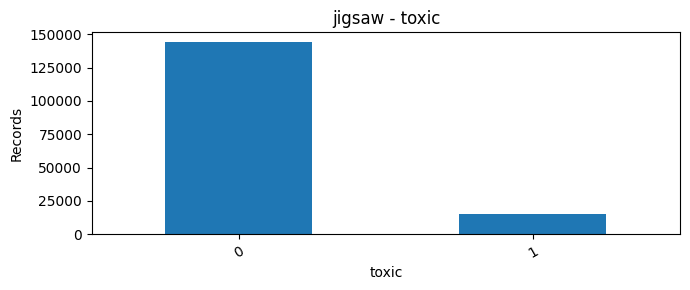


severe_toxic
severe_toxic
0    157976
1      1595
Name: count, dtype: int64


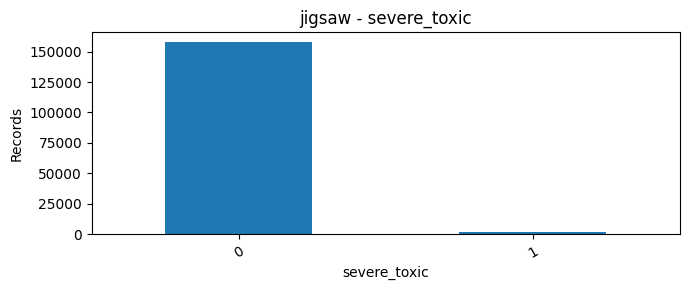


obscene
obscene
0    151122
1      8449
Name: count, dtype: int64


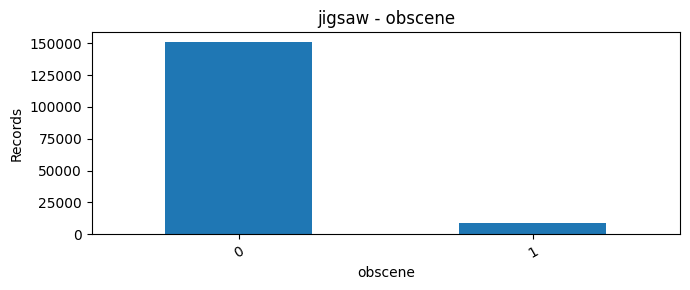


threat
threat
0    159093
1       478
Name: count, dtype: int64


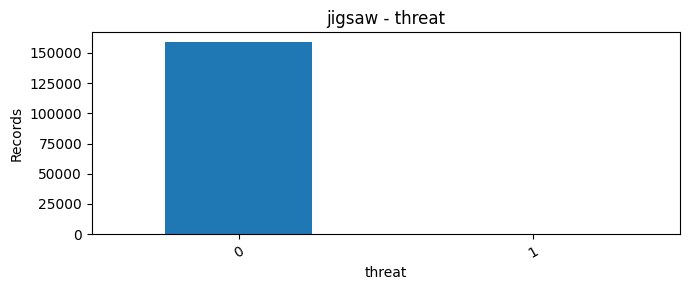


insult
insult
0    151694
1      7877
Name: count, dtype: int64


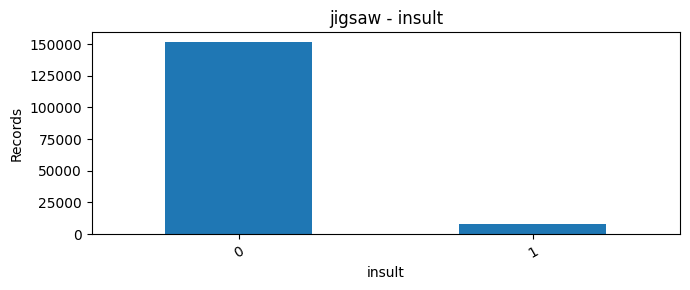


identity_hate
identity_hate
0    158166
1      1405
Name: count, dtype: int64


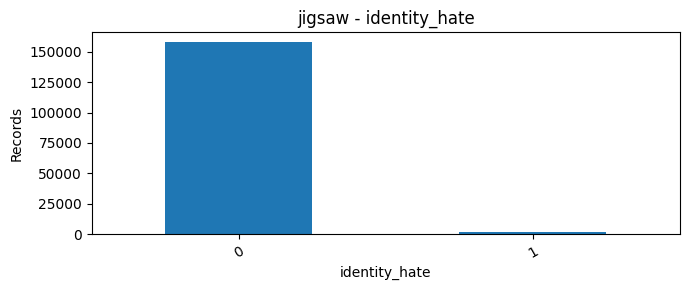


UCI_YOUTUBE

CLASS
CLASS
1    1005
0     951
Name: count, dtype: int64


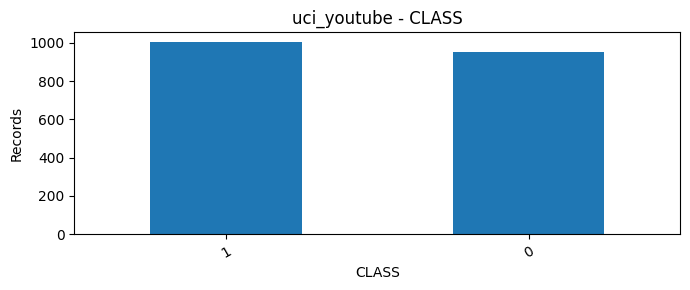


YOUTUBE_45K

label_sentiment
label_sentiment
neutral     22985
positive    18210
negative     3810
Name: count, dtype: int64


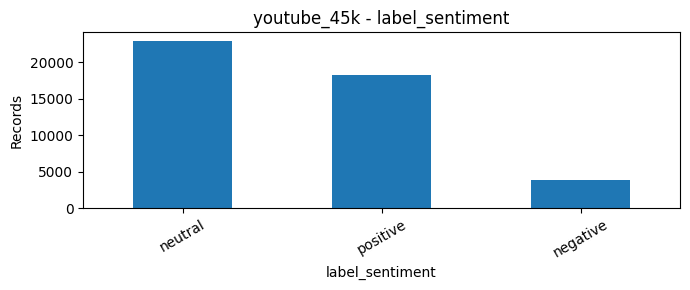


label_toxicity
label_toxicity
non-toxic    43105
toxic         1900
Name: count, dtype: int64


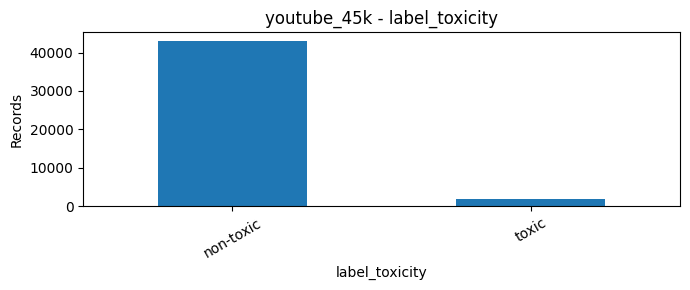


label_spam
label_spam
not spam    44189
spam          816
Name: count, dtype: int64


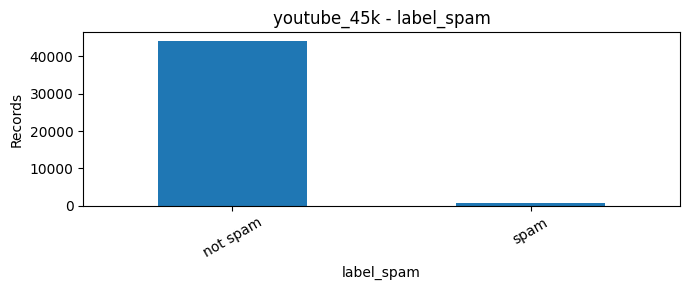


SPAMID_PAIR

spam
spam
0.0    54876
1.0    17998
NaN      125
Name: count, dtype: int64


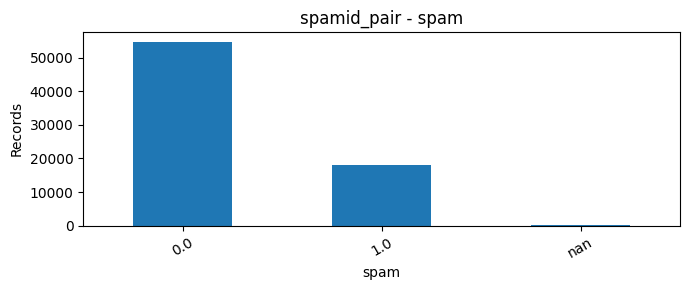

In [ ]:
# label distribution

label_columns = {
    "jigsaw": [
        "toxic",
        "severe_toxic",
        "obscene",
        "threat",
        "insult",
        "identity_hate"
    ],
    "uci_youtube": ["CLASS"],
    "youtube_45k": [
        "label_sentiment",
        "label_toxicity",
        "label_spam"
    ],
    "spamid_pair": ["spam"]
}

label_report = {}

for name, df in datasets.items():
  label_report[name] = {}

  print("\n" + "="*75)
  print(name.upper())
  print("="*75)

  for col in label_columns[name]:
    counts = df[col].value_counts(dropna=False)
    label_report[name][col] = {
        str(k): int(v) for k, v in counts.items()
    }

    print(f"\n{col}")
    print(counts)

    counts.dropna().plot(
        kind="bar",
        figsize=(7, 3),
        title=f"{name} - {col}"
    )

    plt.ylabel("Records")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [ ]:
# language distribution

print("Youtube 45k Langugae Distribution")

language_counts = (
    datasets["youtube_45k"]["language"]
    .value_counts(dropna=False)
)

display(language_counts.to_frame("records"))

print("\nLanguage Percentage")

display(
    (datasets["youtube_45k"]["language"]
    .value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("percentage")
)

Youtube 45k Langugae Distribution


,records
language,
en,15100
NaN,4971
id,4063
so,2158
bn,2067
ml,1589
tl,1431
sw,1291
kn,1101



Language Percentage


,percentage
language,
en,33.55
NaN,11.05
id,9.03
so,4.80
bn,4.59
ml,3.53
tl,3.18
sw,2.87
kn,2.45


In [ ]:
# cross dataset comment overlap

normalized_comments = {}

for name, df in datasets.items():
  col = text_columns[name]
  normalized_comments[name] = set(
      df[col]
      .dropna()
      .astype(str)
      .apply(normalize_text)
  )

overlap_results = []

names = list(normalized_comments.keys())

for i in range(len(names)):
  for j in range(i+1, len(names)):
    name1, name2 = names[i], names[j]
    common = normalized_comments[name1] & normalized_comments[name2]
    result = {
        "dataset1": name1,
        "dataset2": name2,
        "overlapping_unique_comments": len(common)
    }

    overlap_results.append(result)

    print(
        f"{name1} and {name2}"
        f": { len(common)} overlapping comments"
    )

jigsaw and uci_youtube: 2 overlapping comments
jigsaw and youtube_45k: 1 overlapping comments
jigsaw and spamid_pair: 2 overlapping comments
uci_youtube and youtube_45k: 8 overlapping comments
uci_youtube and spamid_pair: 12 overlapping comments
youtube_45k and spamid_pair: 400 overlapping comments


In [ ]:
#saving notebook

import json

final_report = {
    "structural_audit": structural_report,
    "duplicate_audit": duplicate_report,
    "label_distributions": label_report,
    "cross_dataset_overlap": overlap_results
}

report_path = os.path.join(
    REPORTS,
    "notebook_01_quality_audit.json"
)

with open(report_path, "w") as f:
  json.dump(final_report, f, indent=4,default=str)

pd.DataFrame(duplicate_report).to_csv(
    os.path.join(REPORTS,"duplicate_analysis.csv"),
    index=False
)

pd.DataFrame(overlap_results).to_csv(
    os.path.join(REPORTS,"cross_dataset_overlap.csv"),
    index=False
)

print(report_path)

/content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_01_quality_audit.json


In [ ]:
# overlap

yt = datasets["youtube_45k"].copy()
sp = datasets["spamid_pair"].copy()

yt["_normalized"] = yt["comment_text"].apply(normalize_text_v2)
sp["_normalized"] = sp["comment"].apply(normalize_text_v2)

common = set(yt["_normalized"]) & set(sp["_normalized"])
common.discard("")

yt_matches = yt[yt["_normalized"].isin(common)]
sp_matches = sp[sp["_normalized"].isin(common)]

print("Common unique comments: ", len(common))

print("\nYoutube 45k matching records")
display(
    yt_matches[
        ["comment_text", "label_spam", "label_toxicity", "language"]
    ].head(20)
)

print("\nSPAMID-Pair matching records")
display(
    sp_matches[
        ["comment", "spam"]
    ].head(20)
)

Common unique comments:  410

Youtube 45k matching records


,comment_text,label_spam,label_toxicity,language
275,Mast,not spam,toxic,et
976,❤,not spam,non-toxic,NaN
999,❤❤❤❤❤❤❤,spam,non-toxic,NaN
1006,HI,not spam,non-toxic,vi
1009,💜,not spam,non-toxic,NaN
1018,😅,not spam,non-toxic,NaN
1024,❤❤❤❤❤❤❤,spam,non-toxic,NaN
1035,😂😂😂😅,not spam,non-toxic,NaN
1053,❤❤,not spam,non-toxic,NaN
1056,💜💜💜💜💜💜,spam,non-toxic,NaN



SPAMID-Pair matching records


,comment,spam
5,❤️❤️❤️,0.0
21,😍😍😍😍,0.0
25,😍😍😍,0.0
28,🔥,0.0
33,❤️❤️❤️,0.0
35,👏🔥🔥,0.0
39,🔥🔥🔥🔥,0.0
42,❤️❤️❤️,0.0
43,❤️❤️❤️❤️❤️❤️,0.0
46,🔥🔥🔥🔥,0.0


In [ ]:
# duplicate label consistency

label_groups = {
    "jigsaw": ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"],
    "uci_youtube": ["CLASS"],
    "youtube_45k": ["label_sentiment", "label_toxicity", "label_spam"],
    "spamid_pair": ["spam"]
}

for name,df in datasets.items():
  text_col = text_columns[name]
  labels = label_groups[name]

  temp = df[[text_col] + labels].copy()
  temp["_normalized"] = temp[text_col].apply(normalize_text)

  temp = temp[temp['_normalized'] != ""]
  grouped = temp.groupby("_normalized")

  conflicts = []

  for comment,group in grouped:
    if len(group) < 2:
      continue
    for label in labels:
      if group[label].nunique(dropna=False) > 1:
        conflicts.append({
            "comment":comment,
            "label":label,
            "values":group[label].dropna().unique().tolist()
        })

  print("\n",name.upper())
  print("Conflicting duplicate labels",len(conflicts))

  display(pd.DataFrame(conflicts).head(10))


 JIGSAW
Conflicting duplicate labels 56


,comment,label,values
0,""" blocking mardyks excellent work there shii. ...",toxic,"[1, 0]"
1,""" i know what your """"world wide conspiracy"""" y...",toxic,"[1, 0]"
2,""" new award well done!!! the iamthecoinman you...",threat,"[1, 0]"
3,""" saying """"don't be snitty"""" is not a personal...",obscene,"[0, 1]"
4,""" saying """"don't be snitty"""" is not a personal...",insult,"[0, 1]"
5,""" try these important things and maybe you won...",identity_hate,"[1, 0]"
6,""" you might check with the fascists who refuse...",toxic,"[1, 0]"
7,""" you might check with the fascists who refuse...",insult,"[1, 0]"
8,"""""""i want to be a fuck you."""" that's a song. """,insult,"[0, 1]"
9,"""ahhhh . . . . it always feels good to have th...",toxic,"[0, 1]"



 UCI_YOUTUBE
Conflicting duplicate labels 0


""



 YOUTUBE_45K
Conflicting duplicate labels 64


,comment,label,values
0,2035🎉🎉🎉,label_spam,"[spam, not spam]"
1,URL,label_sentiment,"[negative, neutral, positive]"
2,ami ✋✋✋🖐️🖐️🤚🤚🤚,label_spam,"[spam, not spam]"
3,hai bro i know u r covering international nati...,label_spam,"[spam, not spam]"
4,rcb 🏆🏆🏆win 🙏🙏🙏,label_spam,"[spam, not spam]"
5,realme gt 7t,label_sentiment,"[neutral, positive]"
6,subscribe,label_spam,"[spam, not spam]"
7,suparrr....❤❤❤,label_spam,"[spam, not spam]"
8,waah superb 🎉🎉🎉❤❤❤❤,label_spam,"[spam, not spam]"
9,wauu bravo 👏🏾👏🏾👏🏾😘❤❤,label_spam,"[spam, not spam]"



 SPAMID_PAIR
Conflicting duplicate labels 771


,comment,label,values
0,#29wilona,spam,"[0.0, 1.0]"
1,#29wilona❤️❤️,spam,"[0.0, 1.0]"
2,....,spam,"[0.0, 1.0]"
3,0,spam,"[1.0, 0.0]"
4,1+1= i like luna,spam,"[1.0, 0.0]"
5,10k 1000folls,spam,"[1.0, 0.0]"
6,2,spam,"[1.0, 0.0]"
7,:(,spam,"[1.0, 0.0]"
8,@user ❤️,spam,"[1.0, 0.0]"
9,a1,spam,"[0.0, 1.0]"


In [ ]:
# inspect conflicting

for name,df in datasets.items():
  text_col = text_columns[name]
  labels = label_groups[name]

  temp = df[[text_col] + labels].copy()
  temp["_normalized"] = temp[text_col].apply(normalize_text)
  temp = temp[temp["_normalized"] != ""]

  grouped = temp.groupby("_normalized")

  conflict_groups = []

  for comment,group in grouped:
    if len(group) < 2:
      continue

    conflicting_labels = {
        label for label in labels
        if group[label].nunique(dropna=True)>1
    }

    if conflicting_labels:
      conflict_groups.append({
          "comment":comment,
          "rows":len(group),
          "conflicting_labels":conflicting_labels,
          "label_values":{
              label:group[label].dropna().unique().tolist()
              for label in conflicting_labels
          }
      })

  print(f"\n{'='*60}")
  print(name.upper())
  print("Conflicting comment groups",len(conflict_groups))

  display(pd.DataFrame(conflict_groups).head(15))





JIGSAW
Conflicting comment groups 41


,comment,rows,conflicting_labels,label_values
0,""" blocking mardyks excellent work there shii. ...",2,{toxic},"{'toxic': [1, 0]}"
1,""" i know what your """"world wide conspiracy"""" y...",2,{toxic},"{'toxic': [1, 0]}"
2,""" new award well done!!! the iamthecoinman you...",2,{threat},"{'threat': [1, 0]}"
3,""" saying """"don't be snitty"""" is not a personal...",2,"{obscene, insult}","{'obscene': [0, 1], 'insult': [0, 1]}"
4,""" try these important things and maybe you won...",2,{identity_hate},"{'identity_hate': [1, 0]}"
5,""" you might check with the fascists who refuse...",2,"{insult, toxic}","{'insult': [1, 0], 'toxic': [1, 0]}"
6,"""""""i want to be a fuck you."""" that's a song. """,2,{insult},"{'insult': [0, 1]}"
7,"""ahhhh . . . . it always feels good to have th...",3,{toxic},"{'toxic': [0, 1]}"
8,a proposal to cut down on aids less aids would...,2,"{obscene, identity_hate, insult}","{'obscene': [0, 1], 'identity_hate': [0, 1], '..."
9,ankit fadia ankit fadia is not a white hat hac...,2,{toxic},"{'toxic': [0, 1]}"



UCI_YOUTUBE
Conflicting comment groups 0


""



YOUTUBE_45K
Conflicting comment groups 64


,comment,rows,conflicting_labels,label_values
0,2035🎉🎉🎉,4,{label_spam},"{'label_spam': ['spam', 'not spam']}"
1,URL,76,{label_sentiment},"{'label_sentiment': ['negative', 'neutral', 'p..."
2,ami ✋✋✋🖐️🖐️🤚🤚🤚,2,{label_spam},"{'label_spam': ['spam', 'not spam']}"
3,hai bro i know u r covering international nati...,5,{label_spam},"{'label_spam': ['spam', 'not spam']}"
4,rcb 🏆🏆🏆win 🙏🙏🙏,2,{label_spam},"{'label_spam': ['spam', 'not spam']}"
5,realme gt 7t,2,{label_sentiment},"{'label_sentiment': ['neutral', 'positive']}"
6,subscribe,3,{label_spam},"{'label_spam': ['spam', 'not spam']}"
7,suparrr....❤❤❤,2,{label_spam},"{'label_spam': ['spam', 'not spam']}"
8,waah superb 🎉🎉🎉❤❤❤❤,2,{label_spam},"{'label_spam': ['spam', 'not spam']}"
9,wauu bravo 👏🏾👏🏾👏🏾😘❤❤,2,{label_spam},"{'label_spam': ['spam', 'not spam']}"



SPAMID_PAIR
Conflicting comment groups 771


,comment,rows,conflicting_labels,label_values
0,#29wilona,18,{spam},"{'spam': [0.0, 1.0]}"
1,#29wilona❤️❤️,2,{spam},"{'spam': [0.0, 1.0]}"
2,....,3,{spam},"{'spam': [0.0, 1.0]}"
3,0,5,{spam},"{'spam': [1.0, 0.0]}"
4,1+1= i like luna,3,{spam},"{'spam': [1.0, 0.0]}"
5,10k 1000folls,6,{spam},"{'spam': [1.0, 0.0]}"
6,2,19,{spam},"{'spam': [1.0, 0.0]}"
7,:(,3,{spam},"{'spam': [1.0, 0.0]}"
8,@user ❤️,2,{spam},"{'spam': [1.0, 0.0]}"
9,a1,2,{spam},"{'spam': [0.0, 1.0]}"


In [ ]:
def normalize_text_v2(text):
  if pd.isna(text):
    return ""

  text = str(text).lower()
  text = re.sub(r"\s+","",text)
  return text.strip()

In [ ]:
normalize_text

<function __main__.normalize_text(text)>

In [ ]:
normalize_text_v2

<function __main__.normalize_text_v2(text)>

In [ ]:
yt = datasets["youtube_45k"].copy()
sp = datasets["spamid_pair"].copy()

yt["_normalized"] = yt["comment_text"].apply(normalize_text_v2)
sp["_normalized"] = sp["comment"].apply(normalize_text_v2)

def has_text_content(text):
  return any(char.isalnum() for char in str(text))

yt_text = set(yt.loc[yt["_normalized"].apply(has_text_content),"_normalized"])
sp_text = set(yt.loc[sp["_normalized"].apply(has_text_content),"_normalized"])

meaningful_overlap = yt_text & sp_text

print("Youtube 45k",len(yt_text))
print("SPAMID-Pair",len(sp_text))
print("Meaningful overlap",len(meaningful_overlap))

display(pd.DataFrame(meaningful_overlap,columns=["comment"]).head(10))

Youtube 45k 38158
SPAMID-Pair 25817
Meaningful overlap 24870


,comment
0,btslavercartoondenplease❤❤
1,i'mbtsarmy❤💜
2,hissmile❤️❤️👌
3,trpkaliyacontrovercypavideobanateho
4,bugehaafaatepujaagaalebaanuleaachuaabugehaasab...
5,bhaitusirfbjporhindukohimainhighlightbatarahah...
6,andraganarendrasurrenderkibatkrrah..54wapisnal...
7,louispastureisinventerofpatueristion
8,ಅನಂತ್ಅಂಬಾನಿನಿನಗೆಮುಂದೆದೆವರುಒಳ್ಳೆದುಮಾಡ್ತಾನೆ.
9,sabkocamentkarnahiaatahesarmnhiaatibakvaskarrheho
